# 02 RFM Customer Segmentation
Goal: describe each registered customer by Recency, Frequency and Monetary value, score them into named segments, and propose an action per segment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

PROJECT_DIR = Path.cwd().parent
CLEAN_PATH = PROJECT_DIR / "data" / "processed" / "online_retail_clean.parquet"

df = pd.read_parquet(CLEAN_PATH)
print(df.shape)
df.dtypes

(997099, 9)


Invoice                string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             Int64
Country                string
Revenue               float64
dtype: object

In [2]:
cust = df[df["Customer ID"].notna()].copy()

print("Lines:     ", f"{len(cust):,} ({len(cust) / len(df):.1%} of all lines)")
print("Customers: ", f"{cust['Customer ID'].nunique():,}")
print("Revenue:   ", f"{cust['Revenue'].sum() / df['Revenue'].sum():.1%} of total revenue")

Lines:      770,338 (77.3% of all lines)
Customers:  5,839
Revenue:    86.5% of total revenue


In [3]:
snapshot = cust["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot.date())

rfm = cust.groupby("Customer ID").agg(
    last_purchase = ("InvoiceDate", "max"),
    frequency = ("Invoice", "nunique"),
    monetary = ("Revenue", "sum"),
)
rfm["recency"] = (snapshot - rfm["last_purchase"].dt.normalize()).dt.days
rfm = rfm[["recency", "frequency", "monetary"]]

print("Customers:", len(rfm))
print("One-time buyers:", f"{(rfm['frequency'] == 1).mean():.1%}")
rfm.describe().round(1)

Snapshot date: 2011-12-10
Customers: 5839
One-time buyers: 27.6%


,recency,frequency,monetary
count,5839.0,5839.0,5839.0
mean,200.9,6.2,2820.0
std,208.6,12.6,13875.9
min,1.0,1.0,2.9
25%,26.0,1.0,336.1
50%,96.0,3.0,851.0
75%,380.0,7.0,2206.5
max,739.0,369.0,579128.6


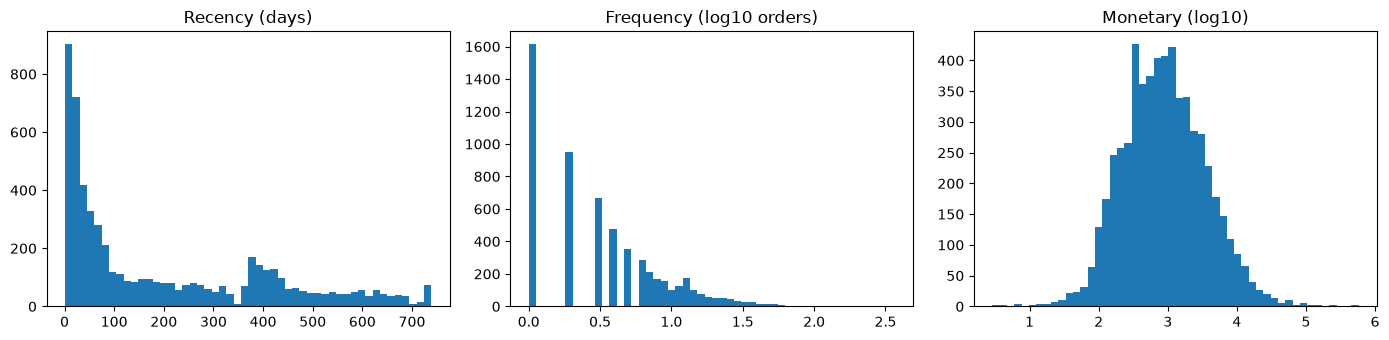

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

axes[0].hist(rfm["recency"], bins=50)
axes[0].set_title("Recency (days)")

axes[1].hist(np.log10(rfm["frequency"]), bins=50)
axes[1].set_title("Frequency (log10 orders)")

axes[2].hist(np.log10(rfm["monetary"]), bins=50)
axes[2].set_title("Monetary (log10)")

plt.tight_layout()
plt.show()

In [5]:
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["RFM"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

print(rfm[["R", "F", "M"]].apply(pd.Series.value_counts))
rfm.head()

      R     F     M
1  1165  1168  1168
2  1170  1168  1168
3  1160  1167  1167
4  1132  1168  1168
5  1212  1168  1168


,recency,frequency,monetary,R,F,M,RFM
Customer ID,,,,,,,
12346,530,2,169.36,1,2,1,121
12347,3,8,4921.53,5,4,5,545
12348,76,5,1658.40,3,4,4,344
12349,19,3,3678.69,5,3,5,535
12350,311,1,294.40,2,1,2,212
